# 07 · Tinh chỉnh MLP bằng RandomizedSearchCV

Dự đoán PM2.5 ở giờ kế tiếp của cùng một trạm. Notebook này theo trình tự của notebook 05 và dùng cấu hình MLP của notebook 06 làm mốc so sánh.

`RandomizedSearchCV` lấy mẫu các tổ hợp từ **5 siêu tham số**. Mỗi tổ hợp được huấn luyện và chấm trên cùng 5 fold theo thời gian. RMSE validation trung bình thấp nhất quyết định cấu hình tốt nhất trong lần tìm kiếm. Tập test được dành cho đánh giá cuối.

Đặt file vào thư mục `notebooks/`, dùng cùng kernel với notebook 06 và chọn **Run All**. Mặc định thử 8 tổ hợp, tương đương 40 lần huấn luyện ở bước tìm kiếm. Notebook chấm lại 5 fold cho cấu hình tốt nhất rồi huấn luyện một mô hình cuối. Mục 8 tự tính lại điểm cấu hình gốc nếu chưa có CSV hợp lệ từ notebook 06.

## 1. Cấu hình và nạp thư viện

- `N_ITER_MLP` là số tổ hợp ngẫu nhiên. Có thể giảm số này để chạy thử nhanh.
- `SAVE_ARTIFACTS = True` xuất mô hình, bảng điểm, biểu đồ và nhật ký ở mục 10. Đặt `False` để xem trong notebook.
- `SAVE_OOF = True` xuất thêm dự đoán chi tiết của từng dòng validation. Mặc định tắt.

In [1]:
import json
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

# Tìm thư mục gốc của đồ án (thư mục chứa src/), chạy được từ gốc hoặc từ notebooks/.
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [CURRENT_DIR, *CURRENT_DIR.parents] if (path / "src").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (thư mục chứa src/).")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Dùng lại mã chung của nhóm (không tự viết lại cách chia dữ liệu).
from src.data_loader import load_data, time_split, cv_folds, TEST_START
from src.features import (
    FEATURE_COLUMNS,
    FFILL_LIMIT,
    PM25_LAGS,
    ROLLING_WINDOWS,
    add_features,
    build_preprocessor,
    split_xy,
)

RANDOM_STATE = 42
N_ITER_MLP = 8
SAVE_ARTIFACTS = True
SAVE_OOF = False

MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
EXPERIMENT_LOG = PROJECT_ROOT / "experiment_log.csv"

# Đồng bộ kiểu biểu đồ với Notebook 02, 03, 04.
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("Thư mục gốc:", PROJECT_ROOT)
print("scikit-learn:", sklearn.__version__)
print("Mốc bắt đầu test:", TEST_START)
print(f"Số tổ hợp MLP: {N_ITER_MLP} | Lưu kết quả: {SAVE_ARTIFACTS} | Lưu OOF: {SAVE_OOF}")

Thư mục gốc: C:\Users\Admin\Documents\GitHub\sgu_finalproject_machinelearning_2026-2027
scikit-learn: 1.7.2
Mốc bắt đầu test: 2016-09-01 00:00:00
Số tổ hợp MLP: 8 | Lưu kết quả: True | Lưu OOF: False


## 2. Nạp dữ liệu và tạo đặc trưng

Dùng `add_features` từ `src/` để tạo 27 đặc trưng và nhãn `target`, tức PM2.5 giờ kế tiếp của cùng trạm. Dòng thiếu nhãn được bỏ vì thiếu số đo thật để chấm.

In [2]:
raw = load_data()
featured = add_features(raw)
labeled = featured.dropna(subset=["target"]).reset_index(drop=True)

print(f"Dữ liệu gốc            : {raw.shape[0]:,} dòng x {raw.shape[1]} cột")
print(f"Sau khi tạo đặc trưng  : {featured.shape[0]:,} dòng x {featured.shape[1]} cột")
print(f"Sau khi bỏ dòng thiếu target: {labeled.shape[0]:,} dòng")
print(f"Số trạm                : {labeled['station'].nunique()}")
print(f"Số đặc trưng đưa vào mô hình: {len(FEATURE_COLUMNS)}")

Dữ liệu gốc            : 420,768 dòng x 19 cột
Sau khi tạo đặc trưng  : 420,768 dòng x 35 cột
Sau khi bỏ dòng thiếu target: 412,017 dòng
Số trạm                : 12
Số đặc trưng đưa vào mô hình: 27


## 3. Chia dữ liệu và tạo đúng 5 lượt validation

Dùng đúng cách chia thời gian của notebook 05 và 06. `folds` chứa chỉ số phần học và phần validation của từng lượt. Phần học luôn đứng trước phần validation. Các nhãn từ ngày 01/09/2016 trở đi được giữ cho test.

In [3]:
train_validation, test = time_split(labeled)
train_validation = train_validation.reset_index(drop=True)
test = test.reset_index(drop=True)

X_tv, y_tv = split_xy(train_validation)   # X = đề bài (27 đặc trưng), y = đáp án (target)
folds = cv_folds(train_validation, n_splits=5)

fold_rows = []
for fold_id, (tr, va) in enumerate(folds, start=1):
    train_times = train_validation.iloc[tr]["target_datetime"]
    validation_times = train_validation.iloc[va]["target_datetime"]
    fold_rows.append({
        "fold": fold_id,
        "train_rows": len(tr),
        "validation_rows": len(va),
        "train_start": train_times.min(),
        "train_end": train_times.max(),
        "validation_start": validation_times.min(),
        "validation_end": validation_times.max(),
    })

fold_table = pd.DataFrame(fold_rows)
display(fold_table)

assert len(folds) == 5, f"Cần đúng 5 lượt, hiện có {len(folds)}."
assert train_validation["target_datetime"].max() < TEST_START
assert test["target_datetime"].min() >= TEST_START
for tr, va in folds:
    assert np.intersect1d(tr, va).size == 0, "Phần học và phần thử bị trùng dòng."
    assert (
        train_validation.iloc[tr]["target_datetime"].max()
        < train_validation.iloc[va]["target_datetime"].min()
    ), "Phần thử không nằm sau phần học."

print(f"Phần học/ôn thi thử: {len(train_validation):,} dòng")
print(f"Phần thi cuối      : {len(test):,} dòng (giữ riêng, KHÔNG dùng trong notebook này)")
print("Kiểm tra thứ tự thời gian và 5 lượt: PASS")

,fold,train_rows,validation_rows,train_start,train_end,validation_start,validation_end
0,1,60258,60595,2013-03-01 01:00:00,2013-09-30 00:00:00,2013-09-30 01:00:00,2014-05-01 17:00:00
1,2,120853,59958,2013-03-01 01:00:00,2014-05-01 17:00:00,2014-05-01 18:00:00,2014-11-30 16:00:00
2,3,180811,59858,2013-03-01 01:00:00,2014-11-30 16:00:00,2014-11-30 17:00:00,2015-07-02 02:00:00
3,4,240669,60217,2013-03-01 01:00:00,2015-07-02 02:00:00,2015-07-02 03:00:00,2016-01-31 14:00:00
4,5,300886,60068,2013-03-01 01:00:00,2016-01-31 14:00:00,2016-01-31 15:00:00,2016-08-31 23:00:00


Phần học/ôn thi thử: 360,954 dòng
Phần thi cuối      : 51,063 dòng (giữ riêng, KHÔNG dùng trong notebook này)
Kiểm tra thứ tự thời gian và 5 lượt: PASS


## 4. Khoảng tìm kiếm tham số

| Siêu tham số | Giá trị thử | Ý nghĩa |
|---|---|---|
| `hidden_layer_sizes` | `(32, 16)`, `(64, 32)`, `(128, 64)` | Số nơ-ron của mỗi lớp ẩn. Cả cặp là một siêu tham số. |
| `learning_rate_init` | `0.0003`, `0.001`, `0.003` | Tốc độ cập nhật trọng số ban đầu của Adam. |
| `alpha` | `0.0001`, `0.001`, `0.01` | Mức phạt L2 để hạn chế trọng số quá lớn. |
| `batch_size` | `256`, `512`, `1024` | Số mẫu dùng trong một lần cập nhật trọng số. |
| `max_iter` | `40`, `60`, `100` | Số vòng học tối đa. MLP có thể dừng sớm hơn theo tiêu chí hội tụ trên train. |

Giữ ReLU, Adam, các điều kiện hội tụ và seed như notebook 06. Tiền xử lý và chuẩn hóa nhãn đều học từ phần train của fold. Đường dẫn `model__regressor__` trỏ vào MLP nằm bên trong bộ chuẩn hóa nhãn.

In [4]:
BASELINE_PARAMS = {
    "hidden_layer_sizes": (64, 32),
    "learning_rate_init": 0.001,
    "alpha": 0.001,
    "batch_size": 512,
    "max_iter": 60,
}

SEARCH_SPACE = {
    "hidden_layer_sizes": [(32, 16), (64, 32), (128, 64)],
    "learning_rate_init": [0.0003, 0.001, 0.003],
    "alpha": [0.0001, 0.001, 0.01],
    "batch_size": [256, 512, 1024],
    "max_iter": [40, 60, 100],
}

PARAM_PREFIX = "model__regressor__"


def build_model(params):
    return Pipeline([
        ("preprocess", build_preprocessor(scale=True)),
        ("model", TransformedTargetRegressor(
            regressor=MLPRegressor(
                **params,
                activation="relu",
                solver="adam",
                tol=0.0002,
                n_iter_no_change=8,
                early_stopping=False,
                random_state=RANDOM_STATE,
            ),
            transformer=StandardScaler(),
        )),
    ])

## 5. Hàm chấm điểm và hàm chạy tìm kiếm

Giống notebook 05, bước tìm kiếm dùng `neg_root_mean_squared_error` vì scikit-learn xếp điểm cao hơn lên trước. Bảng đổi dấu để hiển thị RMSE theo đơn vị µg/m³. Trung bình fold 2–5 là số tham khảo vì phần train của fold 1 chưa có mùa đông. Thứ hạng dựa trên đủ 5 fold.

In [5]:
def regression_metrics(y_true, y_pred):
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
    }


def run_search():
    search = RandomizedSearchCV(
        estimator=build_model(BASELINE_PARAMS),
        param_distributions={
            PARAM_PREFIX + name: values for name, values in SEARCH_SPACE.items()
        },
        n_iter=N_ITER_MLP,
        scoring="neg_root_mean_squared_error",
        cv=folds,
        refit=False,
        random_state=RANDOM_STATE,
        n_jobs=1,
        error_score="raise",
        verbose=2,
    )
    started = time.perf_counter()
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        search.fit(X_tv, y_tv)
    elapsed = time.perf_counter() - started

    results = pd.DataFrame(search.cv_results_)
    fold_cols = [f"split{k}_test_score" for k in range(len(folds))]
    rmse_by_fold = -results[fold_cols].to_numpy()
    table = pd.DataFrame({
        "rmse_mean_5": rmse_by_fold.mean(axis=1),
        "rmse_mean_fold2_5": rmse_by_fold[:, 1:].mean(axis=1),
        "rmse_std_5": rmse_by_fold.std(axis=1, ddof=1),
        **{f"rmse_fold{k + 1}": rmse_by_fold[:, k] for k in range(len(folds))},
        "mean_fit_seconds_per_fold": results["mean_fit_time"],
    })
    for name in SEARCH_SPACE:
        table[name] = results[f"param_{PARAM_PREFIX}{name}"].to_numpy()

    table = table.sort_values("rmse_mean_5", kind="stable", ignore_index=True)
    best_params = {
        name: value.item() if isinstance(value, np.generic) else value
        for name, value in search.best_params_.items()
    }
    best_params = {name[len(PARAM_PREFIX):]: value for name, value in best_params.items()}
    return table, best_params, float(elapsed)

## 6. Chạy tìm kiếm

Mỗi dòng trong bảng là một tổ hợp được thử. Bảng ghi đủ 5 siêu tham số và RMSE ở từng fold. Bước tìm kiếm ẩn cảnh báo chạm giới hạn vòng học để dễ đọc tiến trình. Mục 7 kiểm tra lại cảnh báo này theo từng fold của cấu hình tốt nhất.

In [6]:
search_table, best_params, search_seconds = run_search()
print(f"Tìm kiếm xong trong {search_seconds / 60:.1f} phút.")
print("Bộ tham số tốt nhất trong lần tìm kiếm:", best_params)
display(search_table.round(4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END model__regressor__alpha=0.0001, model__regressor__batch_size=256, model__regressor__hidden_layer_sizes=(128, 64), model__regressor__learning_rate_init=0.003, model__regressor__max_iter=40; total time=  11.0s
[CV] END model__regressor__alpha=0.0001, model__regressor__batch_size=256, model__regressor__hidden_layer_sizes=(128, 64), model__regressor__learning_rate_init=0.003, model__regressor__max_iter=40; total time=  21.0s
[CV] END model__regressor__alpha=0.0001, model__regressor__batch_size=256, model__regressor__hidden_layer_sizes=(128, 64), model__regressor__learning_rate_init=0.003, model__regressor__max_iter=40; total time= 1.1min
[CV] END model__regressor__alpha=0.0001, model__regressor__batch_size=256, model__regressor__hidden_layer_sizes=(128, 64), model__regressor__learning_rate_init=0.003, model__regressor__max_iter=40; total time= 1.2min
[CV] END model__regressor__alpha=0.0001, model__regressor__batch_size=25

,rmse_mean_5,rmse_mean_fold2_5,rmse_std_5,rmse_fold1,rmse_fold2,rmse_fold3,rmse_fold4,rmse_fold5,mean_fit_seconds_per_fold,hidden_layer_sizes,learning_rate_init,alpha,batch_size,max_iter
0,19.6317,17.9965,3.8396,26.1727,15.9833,18.8989,18.5985,18.5052,7.5309,"(32, 16)",0.003,0.0001,256,40
1,19.9792,18.3402,3.7986,26.5354,16.7684,19.2854,19.1170,18.1899,14.5269,"(64, 32)",0.003,0.0010,1024,40
2,20.1912,18.3018,4.3178,27.7488,16.8130,19.1802,18.5661,18.6480,14.4470,"(64, 32)",0.003,0.0100,1024,60
3,20.1960,18.2479,4.4605,27.9881,16.6776,19.2768,18.6118,18.4256,12.3418,"(64, 32)",0.001,0.0100,256,60
4,20.3926,18.3491,4.6649,28.5663,17.0544,19.6983,18.4539,18.1899,17.4771,"(64, 32)",0.003,0.0010,1024,100
5,20.7284,18.5040,5.0115,29.6257,17.8168,19.4895,18.2579,18.4519,28.3476,"(128, 64)",0.003,0.0100,512,100
6,21.5432,19.7366,4.0748,28.7693,18.9242,20.3652,20.0199,19.6373,38.3817,"(128, 64)",0.001,0.0100,1024,60
7,21.5569,19.5849,4.6132,29.4452,17.7846,19.8490,19.1582,21.5476,51.6023,"(128, 64)",0.003,0.0001,256,40


## 7. Chấm lại bộ tham số tốt nhất trên 5 lượt

Tạo pipeline mới cho mỗi fold, chấm MAE, RMSE, R² trên validation và tính RMSE train để kiểm tra chênh lệch. Mỗi fold cho biết MLP đã học bao nhiêu vòng và có chạm giới hạn hay không. RMSE trung bình phải khớp với bảng tìm kiếm trong sai số số học.

Cuối mục, huấn luyện lại cấu hình đã chọn trên toàn bộ train + validation để có mô hình sẵn cho đánh giá cuối.

In [7]:
def evaluate_cv(params, collect_oof=False):
    fold_results, oof_parts = [], []
    cv_started = time.perf_counter()
    for fold_id, (tr, va) in enumerate(folds, start=1):
        X_train, y_train = X_tv.iloc[tr], y_tv.iloc[tr]
        X_val, y_val = X_tv.iloc[va], y_tv.iloc[va]
        model = build_model(params)
        fold_started = time.perf_counter()

        with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as fit_warnings:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(X_train, y_train)
            predictions = model.predict(X_val)
            train_predictions = model.predict(X_train)

        for warning in fit_warnings:
            if not issubclass(warning.category, ConvergenceWarning):
                warnings.warn(warning.message, warning.category)

        metrics = regression_metrics(y_val, predictions)
        train_rmse = regression_metrics(y_train, train_predictions)["rmse"]
        fold_results.append({
            "fold": fold_id,
            **metrics,
            "train_rmse": train_rmse,
            "rmse_gap": metrics["rmse"] - train_rmse,
            "rmse_ratio": metrics["rmse"] / train_rmse if train_rmse else np.nan,
            "runtime_seconds": float(time.perf_counter() - fold_started),
            "train_rows": len(tr),
            "validation_rows": len(va),
            "epochs": model.named_steps["model"].regressor_.n_iter_,
            "hit_iteration_limit": any(
                issubclass(warning.category, ConvergenceWarning) for warning in fit_warnings
            ),
        })

        if collect_oof:
            oof = train_validation.iloc[va][["station", "datetime", "target_datetime"]].copy()
            oof.insert(0, "fold", fold_id)
            oof["y_true"] = y_val.to_numpy()
            oof["y_pred"] = predictions
            oof["residual"] = oof["y_true"] - oof["y_pred"]
            oof_parts.append(oof)

        print(f"Fold {fold_id} | MAE={metrics['mae']:.4f} | RMSE={metrics['rmse']:.4f} | R²={metrics['r2']:.4f}")

    oof_all = pd.concat(oof_parts, ignore_index=True) if collect_oof else None
    return pd.DataFrame(fold_results), oof_all, float(time.perf_counter() - cv_started)


cv_metrics, oof, cv_seconds = evaluate_cv(best_params, collect_oof=SAVE_ARTIFACTS and SAVE_OOF)
recomputed_rmse = float(cv_metrics["rmse"].mean())
search_rmse = float(search_table.loc[0, "rmse_mean_5"])
assert np.isclose(recomputed_rmse, search_rmse, rtol=1e-6), "RMSE chấm lại lệch bảng tìm kiếm."
print(f"RMSE chấm lại = {recomputed_rmse:.4f} | RMSE tìm kiếm = {search_rmse:.4f}")

final_model = build_model(best_params)
started = time.perf_counter()
with threadpool_limits(limits=1):
    final_model.fit(X_tv, y_tv)
final_fit_seconds = float(time.perf_counter() - started)

Fold 1 | MAE=15.9940 | RMSE=26.1727 | R²=0.9176
Fold 2 | MAE=9.5610 | RMSE=15.9833 | R²=0.9497
Fold 3 | MAE=10.6639 | RMSE=18.8989 | R²=0.9317
Fold 4 | MAE=10.2423 | RMSE=18.5985 | R²=0.9598
Fold 5 | MAE=8.8979 | RMSE=18.5052 | R²=0.9107
RMSE chấm lại = 19.6317 | RMSE tìm kiếm = 19.6317


In [8]:
metric_columns = ["mae", "rmse", "r2"]
mean_scores = {metric: float(cv_metrics[metric].mean()) for metric in metric_columns}
cv_summary = pd.DataFrame([
    {"metric": metric, "mean": mean_scores[metric], "std": float(cv_metrics[metric].std(ddof=1))}
    for metric in metric_columns
])

display(cv_metrics.round(4))
display(cv_summary.round(4))
print("Tỉ lệ RMSE validation / train theo fold:", cv_metrics["rmse_ratio"].round(2).tolist())

,fold,mae,rmse,r2,train_rmse,rmse_gap,rmse_ratio,runtime_seconds,train_rows,validation_rows,epochs,hit_iteration_limit
0,1,15.9940,26.1727,0.9176,16.5232,9.6495,1.5840,4.4234,60258,60595,40,True
1,2,9.5610,15.9833,0.9497,17.8029,-1.8197,0.8978,8.4582,120853,59958,40,True
2,3,10.6639,18.8989,0.9317,17.4210,1.4779,1.0848,6.2750,180811,59858,20,False
3,4,10.2423,18.5985,0.9598,17.8579,0.7405,1.0415,8.8132,240669,60217,21,False
4,5,8.8979,18.5052,0.9107,17.2579,1.2473,1.0723,10.9030,300886,60068,22,False


,metric,mean,std
0,mae,11.0718,2.8324
1,rmse,19.6317,3.8396
2,r2,0.9339,0.0208


Tỉ lệ RMSE validation / train theo fold: [1.58, 0.9, 1.08, 1.04, 1.07]


## 8. So sánh trước và sau khi tinh chỉnh

Kết quả trước tuning lấy từ `outputs/mlp_cv_metrics.csv` của notebook 06, đối chiếu số fold và số mẫu mỗi fold. Nếu file thiếu hoặc có cấu trúc fold khác, notebook chấm lại cấu hình gốc bằng cùng cách chia. Cột thay đổi âm nghĩa là RMSE giảm.

In [9]:
baseline_path = OUTPUTS_DIR / "mlp_cv_metrics.csv"
before = pd.read_csv(baseline_path) if baseline_path.is_file() else pd.DataFrame()
fold_columns = ["fold", "train_rows", "validation_rows"]
valid_baseline = (
    set([*fold_columns, "rmse"]).issubset(before.columns)
    and before.sort_values("fold")[fold_columns].reset_index(drop=True).equals(cv_metrics[fold_columns])
    and np.isfinite(before["rmse"]).all()
)
if valid_baseline:
    before = before.sort_values("fold", ignore_index=True)
else:
    print("Tính lại điểm validation của cấu hình gốc.")
    before, _, _ = evaluate_cv(BASELINE_PARAMS)

compare_rows = []
for label, subset in [("TB 5 lượt", slice(None)), ("TB lượt 2–5", slice(1, None))]:
    rmse_before = float(before["rmse"].iloc[subset].mean())
    rmse_after = float(cv_metrics["rmse"].iloc[subset].mean())
    compare_rows.append({
        "phạm vi": label,
        "RMSE trước": rmse_before,
        "RMSE sau": rmse_after,
        "thay đổi": rmse_after - rmse_before,
        "thay đổi (%)": 100 * (rmse_after - rmse_before) / rmse_before,
    })

compare_table = pd.DataFrame(compare_rows)
display(compare_table.round(4))
display(pd.DataFrame([
    {"tham số": name, "trước": str(BASELINE_PARAMS[name]), "sau": str(best_params[name])}
    for name in SEARCH_SPACE
]))

,phạm vi,RMSE trước,RMSE sau,thay đổi,thay đổi (%)
0,TB 5 lượt,20.0840,19.6317,-0.4523,-2.2519
1,TB lượt 2–5,18.0904,17.9965,-0.0940,-0.5194


,tham số,trước,sau
0,hidden_layer_sizes,"(64, 32)","(32, 16)"
1,learning_rate_init,0.001,0.003
2,alpha,0.001,0.0001
3,batch_size,512,256
4,max_iter,60,40


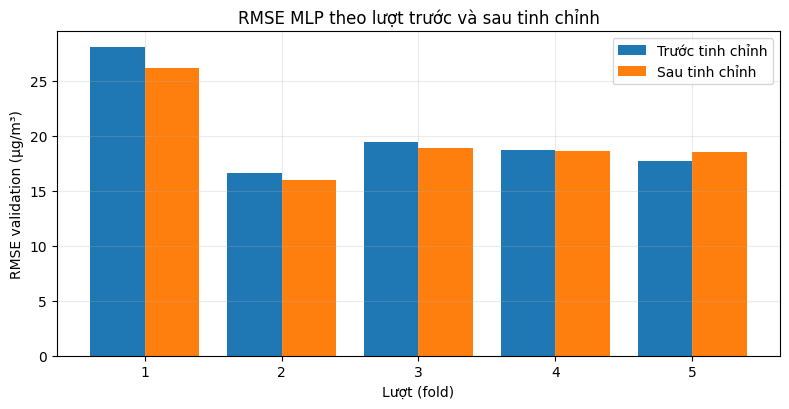

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
positions = cv_metrics["fold"].to_numpy()
ax.bar(positions - 0.2, before["rmse"], width=0.4, label="Trước tinh chỉnh")
ax.bar(positions + 0.2, cv_metrics["rmse"], width=0.4, label="Sau tinh chỉnh")
ax.set(
    xticks=positions,
    xlabel="Lượt (fold)",
    ylabel="RMSE validation (µg/m³)",
    title="RMSE MLP theo lượt trước và sau tinh chỉnh",
)
ax.legend()
fig.tight_layout()
plt.show()

## 9. Xếp hạng theo sổ thí nghiệm (trung bình 5 lượt)

Ghép kết quả mới với các dòng `*_cv5` cùng phiên bản dữ liệu trong `experiment_log.csv`. Bảng chỉ xếp hạng theo validation. Dòng MLP mới có mã `mlp_tuned_cv5`.

In [11]:
DATASET_VERSION = (
    f"beijing_air_quality_standardized.csv; ffill<={FFILL_LIMIT}h; "
    f"lags={'/'.join(map(str, PM25_LAGS))}; "
    f"rolling={'/'.join(map(str, ROLLING_WINDOWS))}"
)
LOG_COLUMNS = ["experiment_id", "model_name", "dataset_version", "mae", "rmse", "r2", "notes"]


EXPERIMENT_ID = "mlp_tuned_cv5"
best_text = ", ".join(f"{key}={value}" for key, value in best_params.items())
log_row = {
    "experiment_id": EXPERIMENT_ID,
    "model_name": "MLP - tuned",
    "dataset_version": DATASET_VERSION,
    **{key: round(value, 6) for key, value in mean_scores.items()},
    "notes": (
        f"Mean of 5 chronological validation folds. RandomizedSearchCV n_iter={len(search_table)}, "
        f"scoring=neg_root_mean_squared_error, seed={RANDOM_STATE}; best params: {best_text}; "
        f"search runtime={search_seconds:.1f}s; final fit={final_fit_seconds:.2f}s. Test not evaluated."
    ),
}


def update_log():
    if EXPERIMENT_LOG.is_file():
        log = pd.read_csv(EXPERIMENT_LOG, encoding="utf-8-sig")
        return pd.concat(
            [log.loc[log["experiment_id"].ne(EXPERIMENT_ID)], pd.DataFrame([log_row])],
            ignore_index=True,
        )
    return pd.DataFrame([log_row], columns=LOG_COLUMNS)


ranking = update_log()
ranking = ranking.loc[
    ranking["experiment_id"].str.endswith("_cv5", na=False)
    & ranking["dataset_version"].eq(DATASET_VERSION)
].sort_values("rmse", ignore_index=True)
display(ranking[["experiment_id", "model_name", "mae", "rmse", "r2"]])

,experiment_id,model_name,mae,rmse,r2
0,random_forest_tuned_cv5,Random Forest Regressor - tuned,10.125407,19.177861,0.937670
1,baseline_linreg_cv5,Linear Regression,10.738039,19.294994,0.936331
2,mlp_tuned_cv5,MLP - tuned,11.071820,19.631728,0.933902
3,baseline_persistence_cv5,Persistence,10.423993,19.966549,0.931829
4,gradient_boosting_tuned_cv5,Gradient Boosting Regressor (HistGradientBoost...,10.522200,20.038430,0.932782
5,mlp_cv5,MLP,11.728151,20.083995,0.931391
6,random_forest_cv5,Random Forest Regressor,10.525595,20.170724,0.930914
7,gradient_boosting_cv5,Gradient Boosting Regressor (HistGradientBoost...,11.074285,21.972551,0.917270


## 10. Lưu mô hình, điểm và sổ thí nghiệm

Khi `SAVE_ARTIFACTS = True`, ô này xuất:

- `models/mlp_tuned.joblib` và `models/mlp_tuned_metadata.json`
- `outputs/tuning_mlp_search_results.csv` với tất cả tổ hợp đã thử
- `outputs/mlp_tuned_cv_metrics.csv` và `outputs/mlp_tuned_cv_summary.csv`
- `outputs/figures/mlp_tuning_rmse_by_fold.png`
- `outputs/mlp_tuned_validation_oof_predictions.csv` nếu bật `SAVE_OOF`

`experiment_log.csv` cập nhật theo mã `mlp_tuned_cv5`. Khi ghi nhật ký nhóm, lấy dòng này cùng bảng kết quả tìm kiếm để ghi lại các tham số đã thử và kết quả validation.

In [12]:
if SAVE_ARTIFACTS:
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

    model_path = MODELS_DIR / "mlp_tuned.joblib"
    metadata_path = MODELS_DIR / "mlp_tuned_metadata.json"
    search_path = OUTPUTS_DIR / "tuning_mlp_search_results.csv"
    metrics_path = OUTPUTS_DIR / "mlp_tuned_cv_metrics.csv"
    summary_path = OUTPUTS_DIR / "mlp_tuned_cv_summary.csv"
    figure_path = FIGURES_DIR / "mlp_tuning_rmse_by_fold.png"
    saved_paths = [model_path, metadata_path, search_path, metrics_path, summary_path, figure_path]

    joblib.dump(final_model, model_path, compress=3)
    sample = X_tv.iloc[:1000]
    with threadpool_limits(limits=1):
        restored_model = joblib.load(model_path)
        np.testing.assert_allclose(restored_model.predict(sample), final_model.predict(sample))

    for table, path in [(search_table, search_path), (cv_metrics, metrics_path), (cv_summary, summary_path)]:
        table.to_csv(path, index=False, encoding="utf-8-sig")
    fig.savefig(figure_path, dpi=150, bbox_inches="tight")
    if SAVE_OOF:
        oof_path = OUTPUTS_DIR / "mlp_tuned_validation_oof_predictions.csv"
        oof.to_csv(oof_path, index=False, encoding="utf-8-sig")
        saved_paths.append(oof_path)

    metadata = {
        "model": "MLPRegressor",
        "created_at": datetime.now().isoformat(timespec="seconds"),
        "sklearn_version": sklearn.__version__,
        "dataset_version": DATASET_VERSION,
        "feature_columns": list(FEATURE_COLUMNS),
        "train_validation_rows": len(X_tv),
        "test_start": str(TEST_START),
        "test_evaluated": False,
        "tuning": {
            "method": "RandomizedSearchCV",
            "n_iter": len(search_table),
            "random_state": RANDOM_STATE,
            "selection_rule": "Lowest mean RMSE over 5 chronological validation folds",
            "search_space": SEARCH_SPACE,
            "baseline_params": BASELINE_PARAMS,
            "best_params": best_params,
            "search_seconds": search_seconds,
        },
        "cv_metrics_mean": mean_scores,
        "cv_total_runtime_seconds": cv_seconds,
        "final_fit_seconds": final_fit_seconds,
        "final_fit_epochs": final_model.named_steps["model"].regressor_.n_iter_,
        "saved_outputs": [path.relative_to(PROJECT_ROOT).as_posix() for path in saved_paths],
    }
    metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
    update_log().to_csv(EXPERIMENT_LOG, index=False, encoding="utf-8-sig")
    print("Kiểm tra nạp lại mô hình: PASS")
    for path in [*saved_paths, EXPERIMENT_LOG]:
        print("Đã lưu:", path.relative_to(PROJECT_ROOT))
else:
    print("Bật SAVE_ARTIFACTS ở mục 1 để xuất kết quả.")

Kiểm tra nạp lại mô hình: PASS
Đã lưu: models\mlp_tuned.joblib
Đã lưu: models\mlp_tuned_metadata.json
Đã lưu: outputs\tuning_mlp_search_results.csv
Đã lưu: outputs\mlp_tuned_cv_metrics.csv
Đã lưu: outputs\mlp_tuned_cv_summary.csv
Đã lưu: outputs\figures\mlp_tuning_rmse_by_fold.png
Đã lưu: experiment_log.csv


## 11. Kết luận

Ô dưới tổng hợp kết quả sau khi chạy. Chênh lệch train–validation và số fold chạm giới hạn vòng học giúp đọc kết quả. Cần xem thêm sự khác biệt giữa các giai đoạn trước khi kết luận học vẹt.

Cấu hình tốt nhất ở đây là cấu hình dẫn đầu trong các tổ hợp được lấy mẫu. Điểm validation có thể lạc quan vì cùng 5 fold được dùng để chọn cấu hình. Tập test dành cho đánh giá sau khi chốt mô hình.

In [13]:
print("Các tham số tốt nhất:", best_params)
for _, row in compare_table.iterrows():
    print(
        f"{row['phạm vi']}: RMSE {row['RMSE trước']:.4f} → {row['RMSE sau']:.4f} µg/m³ "
        f"({row['thay đổi (%)']:+.2f}%)."
    )
if compare_table.loc[0, "thay đổi"] < 0:
    print("Cấu hình tìm được cải thiện RMSE trung bình so với MLP gốc.")
else:
    print("Giữ MLP gốc nếu chọn theo RMSE validation trung bình, vì tuning chưa cải thiện chỉ số này.")

ratio = cv_metrics["rmse_ratio"]
print(f"Tỉ lệ RMSE validation / train: {ratio.min():.2f}–{ratio.max():.2f}.")
print(f"Số fold chạm giới hạn vòng học: {cv_metrics['hit_iteration_limit'].sum()}/{len(folds)}.")
print("Chưa đánh giá trên tập test.")

Các tham số tốt nhất: {'max_iter': 40, 'learning_rate_init': 0.003, 'hidden_layer_sizes': (32, 16), 'batch_size': 256, 'alpha': 0.0001}
TB 5 lượt: RMSE 20.0840 → 19.6317 µg/m³ (-2.25%).
TB lượt 2–5: RMSE 18.0904 → 17.9965 µg/m³ (-0.52%).
Cấu hình tìm được cải thiện RMSE trung bình so với MLP gốc.
Tỉ lệ RMSE validation / train: 0.90–1.58.
Số fold chạm giới hạn vòng học: 2/5.
Chưa đánh giá trên tập test.
